In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# 1. LOAD & VISUALIZE
# =========================================================
df = pd.read_csv("weatherAUS.csv")

# Missing values plot
plt.figure(figsize=(10, 4))
df.isnull().mean().plot(kind='bar', color='coral')
plt.title("Step 1: Missing Data Proportion per Column")
plt.ylabel("Fraction Missing")
plt.tight_layout()
plt.show()

# Target distribution plot
plt.figure(figsize=(5, 3))
sns.countplot(x='RainTomorrow', data=df)
plt.title("Step 1: Target Count (RainTomorrow)")
plt.show()

# =========================================================
# 2. HANDLE MISSING DATA
# =========================================================
# Drop target rows with NaN and drop columns with >35% missing values + Date
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Sunshine', 'Evaporation', 'Cloud9am', 'Cloud3pm', 'Date'])

# Fill numeric columns with median, categorical columns with mode
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# =========================================================
# 3. HANDLE OUTLIERS (IQR Capping on Rainfall)
# =========================================================
# Boxplot before capping
plt.figure(figsize=(4, 3))
sns.boxplot(y=df['Rainfall'])
plt.title("Step 3: Rainfall Outliers")
plt.show()

# Clip Rainfall using IQR
Q1 = df['Rainfall'].quantile(0.25)
Q3 = df['Rainfall'].quantile(0.75)
IQR = Q3 - Q1
df['Rainfall'] = np.clip(df['Rainfall'], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

# =========================================================
# 4. FEATURE ENCODING
# =========================================================
# Map Yes/No to 1/0
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})

# One-hot encode remaining categorical columns
df = pd.get_dummies(df, drop_first=True, dtype=int)

# =========================================================
# 5 & 6. SPLIT DATA & FEATURE SCALING (Pure NumPy / Pandas)
# =========================================================
# Separate X and y
X = df.drop(columns=['RainTomorrow'])
y = df['RainTomorrow']

# 80/20 Train-Test split
split_idx = int(0.8 * len(df))
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()

# Z-score scaling: (X - mean) / std computed on X_train
mean = X_train[num_cols].mean()
std = X_train[num_cols].std()

X_train[num_cols] = (X_train[num_cols] - mean) / std
X_test[num_cols] = (X_test[num_cols] - mean) / std

# Display final shapes
print("Done!")
print("X_train shape:", X_train.shape, "y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape, "y_test shape:", y_test.shape)

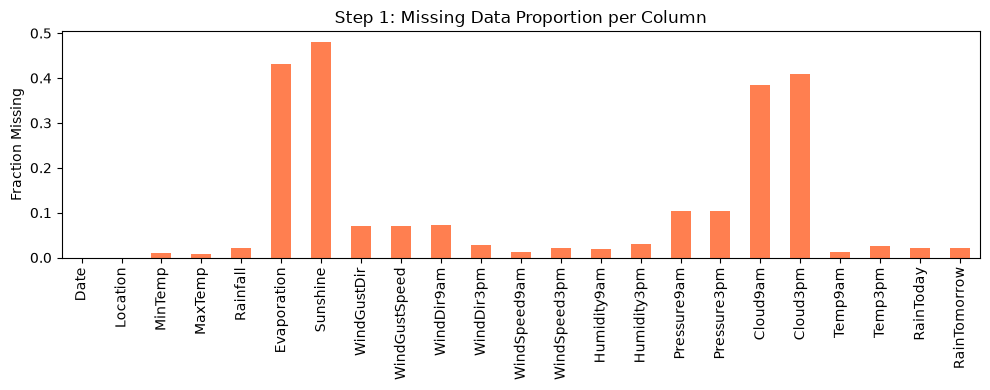

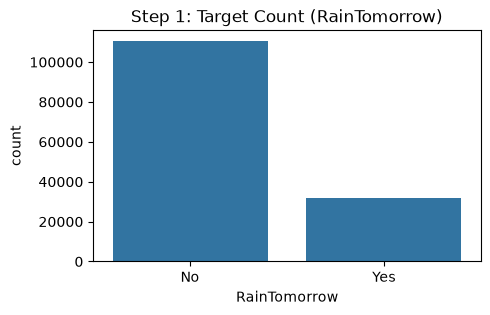

/var/folders/sn/zg9phqwn4llgfxncqcttfsx40000gn/T/ipykernel_9686/1706726890.py:34: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


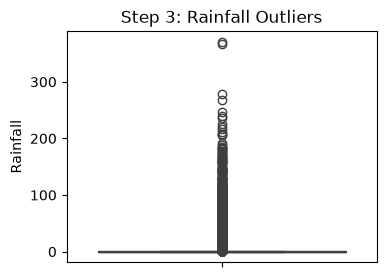

Done!
X_train shape: (113754, 106) y_train shape: (113754,)
X_test shape: (28439, 106) y_test shape: (28439,)


--- Step 1: Initial Dataset Inspection ---
Total Rows: 145460, Total Columns: 23


/var/folders/sn/zg9phqwn4llgfxncqcttfsx40000gn/T/ipykernel_9686/2142001250.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_pct.index, y=missing_pct.values, palette="magma")


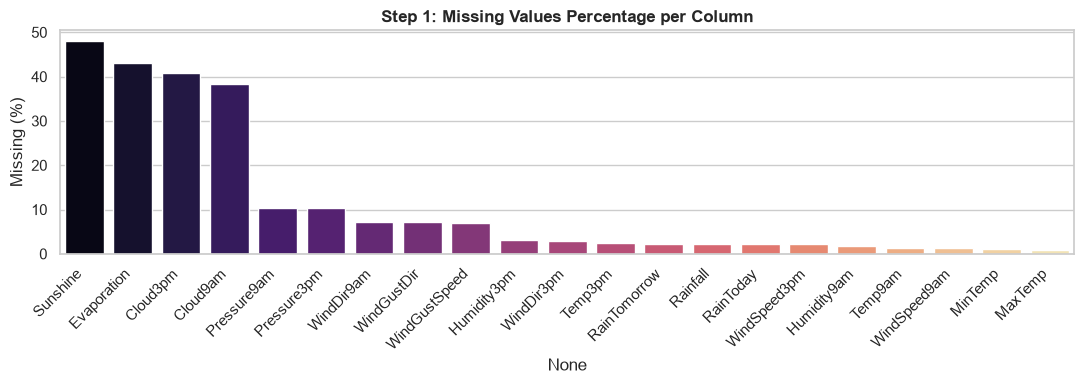

/var/folders/sn/zg9phqwn4llgfxncqcttfsx40000gn/T/ipykernel_9686/2142001250.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='RainTomorrow', palette='Set2')


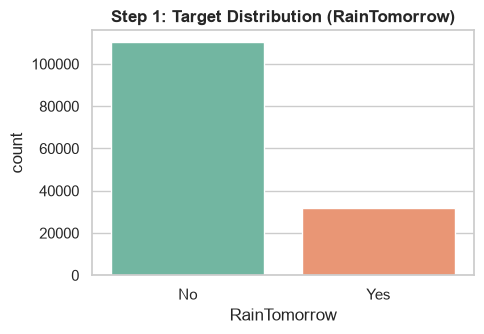

/var/folders/sn/zg9phqwn4llgfxncqcttfsx40000gn/T/ipykernel_9686/2142001250.py:48: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns.drop('RainTomorrow').tolist()


Remaining missing values: 0


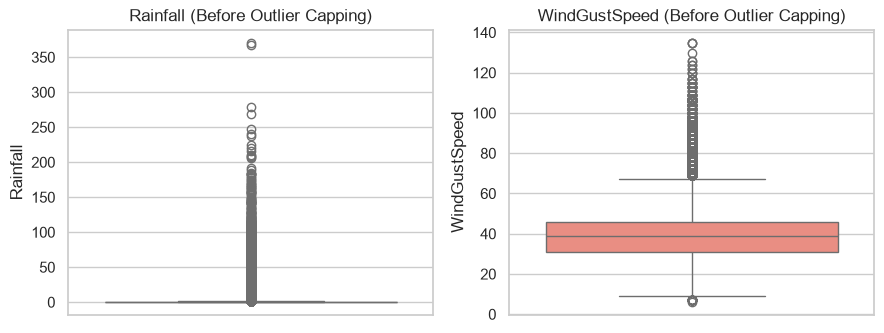

Outliers handled via IQR boundary clipping.
Dimensions after encoding: (142193, 107)

--- Final Dataset Summary ---
X_train shape: (113754, 106) | y_train shape: (113754,)
X_test shape:  (28439, 106)  | y_test shape:  (28439,)

--- 1. Continuous Numerical Columns (Scaled to Decimals / Z-Scores) ---


,MinTemp,MaxTemp,Rainfall,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Temp9am,Temp3pm
0,-0.795918,-1.436441,1.823811,0.113564,1.181184,0.407089,1.642899,2.263949,-2.360681,-1.472000,-1.294812,-1.479213
1,0.159005,-0.691380,-0.632308,0.686801,1.181184,0.170302,0.218138,1.046967,1.473894,1.277585,-0.429526,-0.679234
2,-0.467174,-0.072838,-0.632308,1.014365,1.415082,0.170302,-1.259393,-1.289638,1.844027,1.591396,-0.290462,0.120745
3,0.487749,0.405126,-0.632308,0.359237,1.181184,0.051908,-1.101086,-0.559449,-0.658070,-0.814491,0.080375,0.382556
4,-0.044503,1.206419,-0.632308,2.365567,-0.923901,0.051908,1.062441,-1.289638,-1.620415,-2.129509,-0.120495,0.833453



--- 2. Categorical Dummy Columns (Preserved as Pure 0 and 1) ---


,RainToday,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,...,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
0,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)

df = pd.read_csv("weatherAUS.csv")

print("--- Step 1: Initial Dataset Inspection ---")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")

# Visual 1: Missing values percentage bar chart
plt.figure(figsize=(11, 4))
missing_pct = (df.isnull().mean() * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
sns.barplot(x=missing_pct.index, y=missing_pct.values, palette="magma")
plt.xticks(rotation=45, ha='right')
plt.title("Step 1: Missing Values Percentage per Column", weight='bold')
plt.ylabel("Missing (%)")
plt.tight_layout()
plt.show()

# Visual 2: Target Variable Distribution (Class Balance)
plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x='RainTomorrow', palette='Set2')
plt.title("Step 1: Target Distribution (RainTomorrow)", weight='bold')
plt.tight_layout()
plt.show()

# A. Drop rows missing the target variable
df = df.dropna(subset=['RainTomorrow']).copy()

# B. Drop columns with excessive missing data (>35%) and non-predictive Date
cols_to_drop = ['Sunshine', 'Evaporation', 'Cloud9am', 'Cloud3pm', 'Date']
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

# C. Separate numeric and categorical column lists
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.drop('RainTomorrow').tolist()

# D. Vectorized Imputation: Median for numeric, Mode for categorical
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(f"Remaining missing values: {df.isnull().sum().sum()}")

# Visual 3: Inspect outliers before clipping
plt.figure(figsize=(9, 3.5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Rainfall'], color='skyblue')
plt.title("Rainfall (Before Outlier Capping)")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['WindGustSpeed'], color='salmon')
plt.title("WindGustSpeed (Before Outlier Capping)")
plt.tight_layout()
plt.show()

# Vectorized IQR clipping on skewed weather metrics
outlier_cols = ['Rainfall', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm']
for col in outlier_cols:
    if col in df.columns:
        q25 = df[col].quantile(0.25)
        q75 = df[col].quantile(0.75)
        iqr = q75 - q25
        lower = q25 - (1.5 * iqr)
        upper = q75 + (1.5 * iqr)
        df[col] = np.clip(df[col], lower, upper)

print("Outliers handled via IQR boundary clipping.")


df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})
if 'RainToday' in df.columns:
    df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
    if 'RainToday' in cat_cols:
        cat_cols.remove('RainToday')

# One-hot encoding for multi-class nominal features (Location, Wind directions)
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print(f"Dimensions after encoding: {df.shape}")


# Separate feature matrix (X) and target vector (y)
X = df.drop(columns=['RainTomorrow']).copy()
y = df['RainTomorrow'].copy()

# Shuffle with fixed seed and split (80% train / 20% test)
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
split_idx = int(0.8 * len(df_shuffled))

train_df = df_shuffled.iloc[:split_idx]
test_df  = df_shuffled.iloc[split_idx:]

X_train = train_df.drop(columns=['RainTomorrow']).copy()
y_train = train_df['RainTomorrow'].copy()

X_test  = test_df.drop(columns=['RainTomorrow']).copy()
y_test  = test_df['RainTomorrow'].copy()

# Scale ONLY continuous numerical columns (prevents dummy 0/1 from becoming decimals)
scale_cols = [c for c in num_cols if c in X_train.columns]

# Compute z-score parameters exclusively on X_train to prevent data leakage
train_mean = X_train[scale_cols].mean()
train_std  = X_train[scale_cols].std().replace(0, 1)

X_train[scale_cols] = (X_train[scale_cols] - train_mean) / train_std
X_test[scale_cols]  = (X_test[scale_cols] - train_mean) / train_std

print("\n--- Final Dataset Summary ---")
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")


print("\n--- 1. Continuous Numerical Columns (Scaled to Decimals / Z-Scores) ---")
display(X_train[scale_cols].head())

encoded_dummy_cols = [c for c in X_train.columns if c not in scale_cols]
print("\n--- 2. Categorical Dummy Columns (Preserved as Pure 0 and 1) ---")
display(X_train[encoded_dummy_cols].head())

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------
# Step 1: Load Data & Prune Leaky Target Column / Date
# ---------------------------------------------------------
df = pd.read_csv("weatherAUS.csv")

# Drop leaky target column (RISK_MM) and Date
# Note: 'Location' is kept here so we can use it for city-wise outlier capping below
df = df.drop(columns=["RISK_MM", "Date"], errors="ignore")

# ---------------------------------------------------------
# Step 2: Handle Missing Data
# ---------------------------------------------------------
# Drop rows where target variable is missing
df = df.dropna(subset=["RainTomorrow"])

# Drop columns with >35% missing values
df = df.drop(
    columns=["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"], errors="ignore"
)

# Impute skewed numeric features with median
skewed_cols = ["Rainfall", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]
for col in skewed_cols:
  if col in df.columns:
    df[col] = df[col].fillna(df[col].median())

# Impute symmetrical numeric features with mean
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Impute categorical features with mode
cat_cols = df.select_dtypes(include=["object"]).columns
for col in cat_cols:
  df[col] = df[col].fillna(df[col].mode()[0])

# ---------------------------------------------------------
# Step 3: Handle Outliers (City-Wise IQR Capping)
# ---------------------------------------------------------
# Define the capping function for a single city's series
def cap_outliers_iqr(series):
  q1 = series.quantile(0.25)
  q3 = series.quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  return series.clip(lower=lower_bound, upper=upper_bound)


# Apply city-by-city capping using groupby('Location')
cols_to_cap = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "WindGustSpeed",
    "WindSpeed9am",
    "WindSpeed3pm",
]
for col in cols_to_cap:
  if col in df.columns:
    df[col] = df.groupby("Location")[col].transform(cap_outliers_iqr)

# ---------------------------------------------------------
# Step 4: Correlation Matrix & Multicollinearity Removal
# ---------------------------------------------------------
# Compute correlation matrix on numeric features
corr_matrix = df.corr(numeric_only=True)

# Visualize with Seaborn Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Matrix Before Dropping Redundant Features")
plt.show()

# Drop redundant features where |r| > 0.85:
# - Temp9am correlates strongly with MinTemp (~0.90)
# - Temp3pm correlates strongly with MaxTemp (~0.97)
# - Pressure3pm correlates strongly with Pressure9am (~0.96)
# Also drop 'Location' now that city-wise outlier capping is complete
redundant_cols = ["Temp9am", "Temp3pm", "Pressure3pm", "Location"]
df = df.drop(columns=redundant_cols, errors="ignore")

# ---------------------------------------------------------
# Step 5: Categorical Encoding
# ---------------------------------------------------------
# Binary map for binary features and target
df["RainToday"] = df["RainToday"].map({"No": 0, "Yes": 1})
df["RainTomorrow"] = df["RainTomorrow"].map({"No": 0, "Yes": 1})

# One-hot encoding for nominal categories (Wind Directions)
df = pd.get_dummies(
    df,
    columns=["WindGustDir", "WindDir9am", "WindDir3pm"],
    drop_first=True,
    dtype=int,
)

# ---------------------------------------------------------
# Step 6: Feature Scaling (Standardization)
# ---------------------------------------------------------
scale_cols = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "WindGustSpeed",
    "WindSpeed9am",
    "WindSpeed3pm",
    "Humidity9am",
    "Humidity3pm",
    "Pressure9am",
]

for col in scale_cols:
  if col in df.columns:
    df[col] = (df[col] - df[col].mean()) / df[col].std()

# ---------------------------------------------------------
# Step 7: Train-Test Split (NumPy)
# ---------------------------------------------------------
X = df.drop(columns=["RainTomorrow"])
y = df["RainTomorrow"]

np.random.seed(42)
indices = np.random.permutation(len(df))
train_len = int(0.8 * len(df))

X_train, X_test = X.iloc[indices[:train_len]], X.iloc[indices[train_len:]]
y_train, y_test = y.iloc[indices[:train_len]], y.iloc[indices[train_len:]]

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

/var/folders/sn/zg9phqwn4llgfxncqcttfsx40000gn/T/ipykernel_3427/3135098840.py:37: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object"]).columns


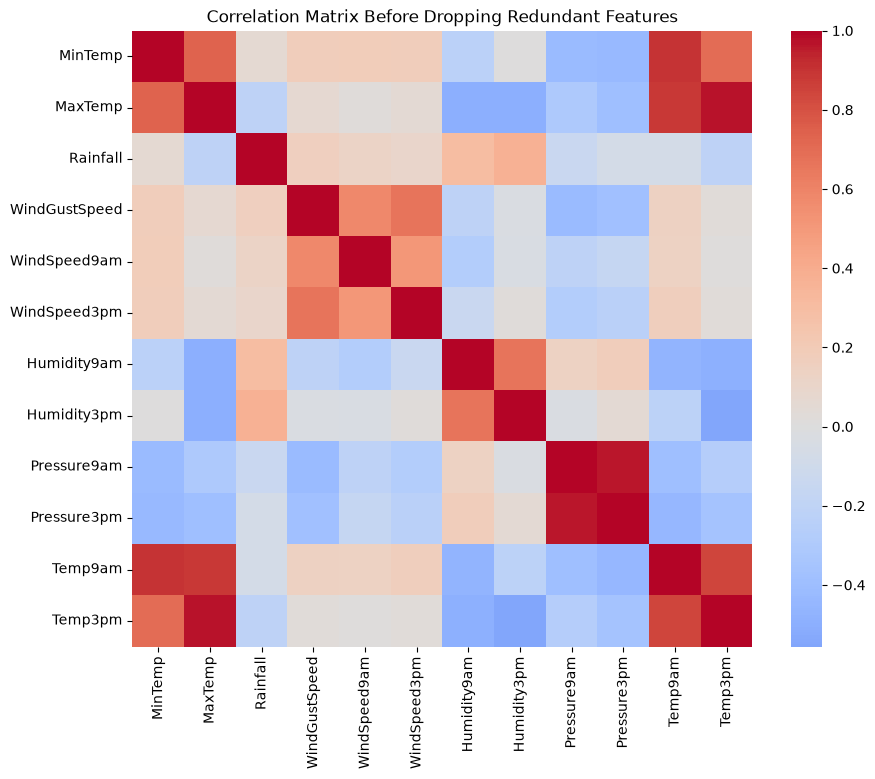

X_train shape: (113754, 55)
X_test shape: (28439, 55)
y_train shape: (113754,)
y_test shape: (28439,)


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------
# Step 1: Load Data & Prune Leaky Target Column / Date
# ---------------------------------------------------------
df = pd.read_csv("weatherAUS.csv")

# Drop leaky target column (RISK_MM) and Date
# Note: 'Location' is kept here so we can use it for city-wise outlier capping below
df = df.drop(columns=["RISK_MM", "Date"], errors="ignore")

# ---------------------------------------------------------
# Step 2: Handle Missing Data
# ---------------------------------------------------------
# Drop rows where target variable is missing
df = df.dropna(subset=["RainTomorrow"])

# Drop columns with >35% missing values
df = df.drop(
    columns=["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"], errors="ignore"
)

# Impute skewed numeric features with median
skewed_cols = ["Rainfall", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]
for col in skewed_cols:
  if col in df.columns:
    df[col] = df[col].fillna(df[col].median())

# Impute symmetrical numeric features with mean
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Impute categorical features with mode
cat_cols = df.select_dtypes(include=["object"]).columns
for col in cat_cols:
  df[col] = df[col].fillna(df[col].mode()[0])

# ---------------------------------------------------------
# Step 3: Handle Outliers (City-Wise IQR Capping)
# ---------------------------------------------------------
# Define the capping function for a single city's series
def cap_outliers_iqr(series):
  q1 = series.quantile(0.25)
  q3 = series.quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  return series.clip(lower=lower_bound, upper=upper_bound)


# Apply city-by-city capping using groupby('Location')
cols_to_cap = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "WindGustSpeed",
    "WindSpeed9am",
    "WindSpeed3pm",
]
for col in cols_to_cap:
  if col in df.columns:
    df[col] = df.groupby("Location")[col].transform(cap_outliers_iqr)

# ---------------------------------------------------------
# Step 4: Correlation Matrix & Multicollinearity Removal
# ---------------------------------------------------------
# Compute correlation matrix on numeric features
corr_matrix = df.corr(numeric_only=True)

# Visualize with Seaborn Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Matrix Before Dropping Redundant Features")
plt.show()

# Drop redundant features where |r| > 0.85:
# - Temp9am correlates strongly with MinTemp (~0.90)
# - Temp3pm correlates strongly with MaxTemp (~0.97)
# - Pressure3pm correlates strongly with Pressure9am (~0.96)
# Also drop 'Location' now that city-wise outlier capping is complete
redundant_cols = ["Temp9am", "Temp3pm", "Pressure3pm", "Location"]
df = df.drop(columns=redundant_cols, errors="ignore")

# ---------------------------------------------------------
# Step 5: Categorical Encoding
# ---------------------------------------------------------
# Binary map for binary features and target
df["RainToday"] = df["RainToday"].map({"No": 0, "Yes": 1})
df["RainTomorrow"] = df["RainTomorrow"].map({"No": 0, "Yes": 1})

# One-hot encoding for nominal categories (Wind Directions)
df = pd.get_dummies(
    df,
    columns=["WindGustDir", "WindDir9am", "WindDir3pm"],
    drop_first=True,
    dtype=int,
)

# ---------------------------------------------------------
# Step 6: Feature Scaling (Standardization)
# ---------------------------------------------------------
scale_cols = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "WindGustSpeed",
    "WindSpeed9am",
    "WindSpeed3pm",
    "Humidity9am",
    "Humidity3pm",
    "Pressure9am",
]

for col in scale_cols:
  if col in df.columns:
    df[col] = (df[col] - df[col].mean()) / df[col].std()

# ---------------------------------------------------------
# Step 7: Train-Test Split (NumPy)
# ---------------------------------------------------------
X = df.drop(columns=["RainTomorrow"])
y = df["RainTomorrow"]

np.random.seed(42)
indices = np.random.permutation(len(df))
train_len = int(0.8 * len(df))

X_train, X_test = X.iloc[indices[:train_len]], X.iloc[indices[train_len:]]
y_train, y_test = y.iloc[indices[:train_len]], y.iloc[indices[train_len:]]

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")
